# Loan Eligibility Prediction — Build It Yourself

Use this notebook as a guided class project. Run one cell at a time, inspect the output, and write your own observations in the reflection prompts. The goal is to predict `Loan_Status` (`Y` = eligible, `N` = not eligible).

**Before you start:** run Jupyter from this project folder. The assignment notes mention EMI, but the provided CSV files do not contain an EMI column. We will use the fields that are actually supplied.


## 1. Import the tools

Pandas helps us inspect tables; Matplotlib and Seaborn help with charts; scikit-learn provides preprocessing and classification models. If an import fails, install the dependencies using the README instructions and restart the notebook kernel.

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Load the data

We keep `Loan_ID` to identify rows later, but we will not use it as a predictor.

In [56]:
train = pd.read_csv("data/loan_train.csv")
test = pd.read_csv("data/loan_test.csv")

print("Training shape:", train.shape)
print("Test shape:", test.shape)
display(train.head())


Training shape: (614, 13)
Test shape: (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**Your turn:** In a Markdown cell, write down what one row represents and which column you are trying to predict.

## 3. Explore the training data

Check data types, summary statistics, missing values, and the number of approvals and rejections.

In [60]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [62]:
display(train.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


In [64]:
missing = train.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))


,missing_count
Credit_History,50
Self_Employed,32
LoanAmount,22
Dependents,15
Loan_Amount_Term,14
Gender,13
Married,3


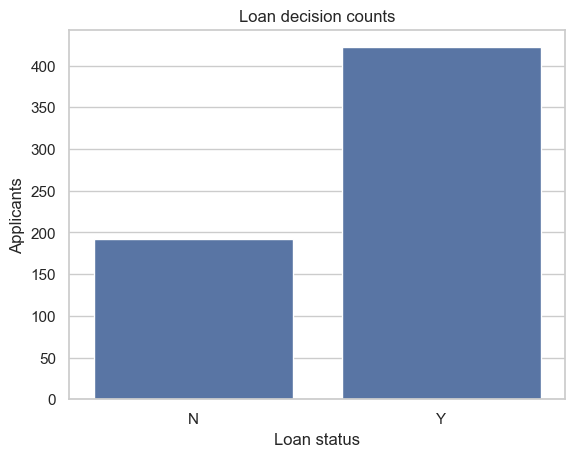

Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [66]:
ax = sns.countplot(data=train, x="Loan_Status", order=["N", "Y"])
ax.set(title="Loan decision counts", xlabel="Loan status", ylabel="Applicants")
plt.show()
print(train["Loan_Status"].value_counts())


**Your turn:** Are the classes balanced? Which columns have missing values? Why should we avoid filling missing values using information from the test set?

## 4. Look for patterns

These plots help form hypotheses. They do not prove that any feature causes approval.

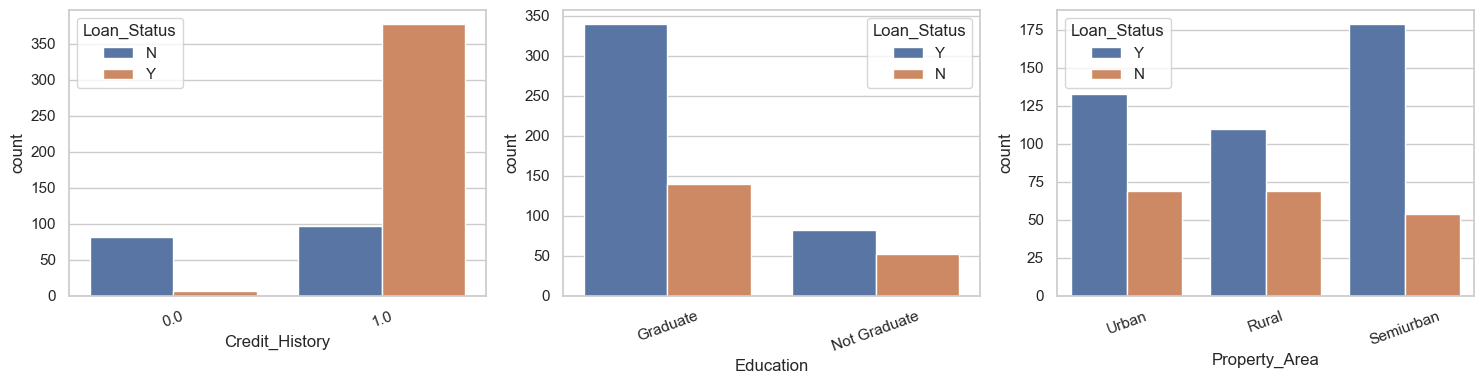

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=train, x="Credit_History", hue="Loan_Status", ax=axes[0])
sns.countplot(data=train, x="Education", hue="Loan_Status", ax=axes[1])
sns.countplot(data=train, x="Property_Area", hue="Loan_Status", ax=axes[2])
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


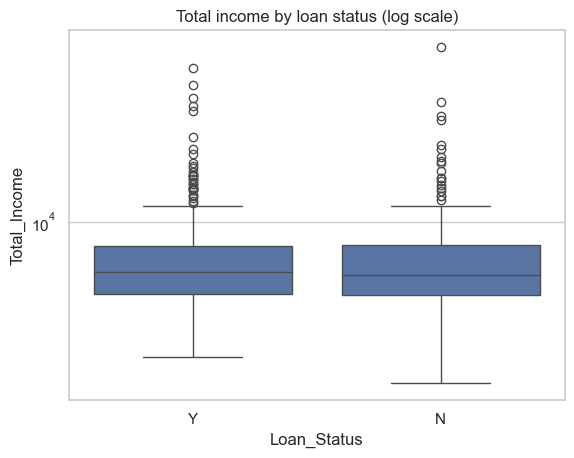

In [71]:
train["Total_Income"] = train["ApplicantIncome"] + train["CoapplicantIncome"]
sns.boxplot(data=train, x="Loan_Status", y="Total_Income")
plt.yscale("log")
plt.title("Total income by loan status (log scale)")
plt.show()


**Your turn:** Write two observations from the charts. Keep in mind that differences in this dataset do not guarantee the model will generalize.

## 5. Prepare features and target

We map `N` to 0 and `Y` to 1. The ID is excluded from the input features. We split the data before fitting imputers or encoders so validation rows do not influence preprocessing.

In [76]:
target = train["Loan_Status"].map({"N": 0, "Y": 1})
X = train.drop(columns=["Loan_Status", "Loan_ID"])
X_train, X_valid, y_train, y_valid = train_test_split(
    X, target, test_size=0.20, random_state=42, stratify=target
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Training approval rate:", round(y_train.mean(), 3))
print("Validation approval rate:", round(y_valid.mean(), 3))


Training rows: 491
Validation rows: 123
Training approval rate: 0.686
Validation approval rate: 0.691


## 6. Build the preprocessing steps

Numeric gaps are filled with the median and scaled. Category gaps are filled with the most common category, then categories are one-hot encoded. A pipeline applies these steps consistently during validation and training.

In [79]:
categorical_columns = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_columns = [c for c in X.columns if c not in categorical_columns]

numeric_prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_prep = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_prep, numeric_columns),
    ("categorical", categorical_prep, categorical_columns),
])

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)


Numeric columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Total_Income']
Categorical columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


## 7. Train a first model: logistic regression

This is a useful baseline. We will evaluate it on the held-out validation set.

In [82]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_valid)
logistic_prob = logistic_model.predict_proba(X_valid)[:, 1]

print("Accuracy:", round(accuracy_score(y_valid, logistic_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_valid, logistic_prob), 3))
print(classification_report(y_valid, logistic_pred, target_names=["Not eligible", "Eligible"], zero_division=0))


Accuracy: 0.829
ROC-AUC: 0.855
              precision    recall  f1-score   support

Not eligible       0.73      0.71      0.72        38
    Eligible       0.87      0.88      0.88        85

    accuracy                           0.83       123
   macro avg       0.80      0.80      0.80       123
weighted avg       0.83      0.83      0.83       123



## 8. Read the errors

A confusion matrix shows correct and incorrect predictions by class. Consider which error matters most in a real lending context; this classroom model is not suitable for real credit decisions.

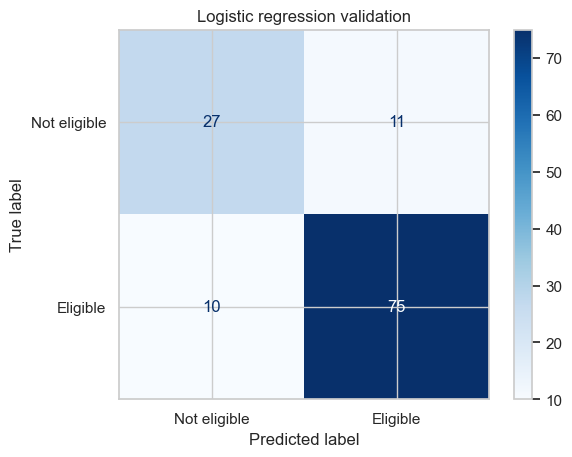

In [85]:
ConfusionMatrixDisplay.from_predictions(
    y_valid, logistic_pred, display_labels=["Not eligible", "Eligible"], cmap="Blues"
)
plt.title("Logistic regression validation")
plt.show()


**Your turn:** Explain precision and recall in this loan eligibility context. Which kind of mistake would you want to investigate more, and why?

## 9. Compare a random forest

A random forest can capture nonlinear patterns. Compare it on the same held-out data using ROC-AUC and the class report.

In [89]:
forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2,
        class_weight="balanced", random_state=42
    )),
])
forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_valid)
forest_prob = forest_model.predict_proba(X_valid)[:, 1]

print("Accuracy:", round(accuracy_score(y_valid, forest_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_valid, forest_prob), 3))
print(classification_report(y_valid, forest_pred, target_names=["Not eligible", "Eligible"], zero_division=0))


Accuracy: 0.797
ROC-AUC: 0.826
              precision    recall  f1-score   support

Not eligible       0.71      0.58      0.64        38
    Eligible       0.83      0.89      0.86        85

    accuracy                           0.80       123
   macro avg       0.77      0.74      0.75       123
weighted avg       0.79      0.80      0.79       123



In [91]:
scores = pd.DataFrame({
    "model": ["Logistic regression", "Random forest"],
    "validation_roc_auc": [
        roc_auc_score(y_valid, logistic_prob),
        roc_auc_score(y_valid, forest_prob),
    ],
})
display(scores.sort_values("validation_roc_auc", ascending=False))


,model,validation_roc_auc
0,Logistic regression,0.855108
1,Random forest,0.826316


**Your turn:** Which model performed better by ROC-AUC on this split? Does that mean it will always perform better on new applicants?

## 10. Fit the chosen model on all labeled rows

Choose based on your validation results and explain that choice in your project report. The cell below selects the higher validation ROC-AUC automatically.

In [95]:
if roc_auc_score(y_valid, forest_prob) > roc_auc_score(y_valid, logistic_prob):
    chosen_model = forest_model
    chosen_name = "Random forest"
else:
    chosen_model = logistic_model
    chosen_name = "Logistic regression"

chosen_model.fit(X, target)
print("Final model:", chosen_name)


Final model: Logistic regression


## 11. Predict the test applicants and create the submission

The sample file uses `Loan_ID` and a numeric `Loan_Status` column. We preserve test IDs and output 0/1 predictions.

In [101]:
test["Total_Income"] = test["ApplicantIncome"] + test["CoapplicantIncome"]

test_X = test.drop(columns=["Loan_ID"])
test_predictions = chosen_model.predict(test_X).astype(int)

submission = pd.DataFrame({
    "Loan_ID": test["Loan_ID"],
    "Loan_Status": test_predictions,
})

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
submission.to_csv(output_dir / "submission.csv", index=False)

display(submission.head())
print("Saved", len(submission), "predictions to", output_dir / "submission.csv")

,Loan_ID,Loan_Status
0,LP001015,1
1,LP001022,1
2,LP001031,1
3,LP001035,1
4,LP001051,0


Saved 367 predictions to outputs/submission.csv


## 12. Wrap up

In your report or presentation, summarize:

1. The problem and target variable.
2. What you found during data exploration.
3. How missing values and categorical variables were handled.
4. Validation metrics for both models and why you selected one.
5. Limitations: small dataset, class imbalance, one validation split, and no EMI field in the supplied data.

**Extension ideas:** try cross-validation, tune model parameters, examine feature importance carefully, or create a total-income feature in a leakage-safe preprocessing pipeline. Record each change and compare it with the baseline.